# Module 5 - Data Visualizations in Python

**Name:** Clement Scaccia  
**Course:** Data Visualization  
**Tools:** Python, pandas, matplotlib

Three visualizations made from my cleaned data sets. They're different from my Excel charts (in `../Excel/Module5_Visualizations.xlsx`) because I used Python for charts that are hard to build in Excel: a heatmap, a binned distribution, and a stacked player breakdown.

| # | Chart | Data |
|---|---|---|
| 1 | Heatmap of monthly inflation, 2015-2026 | cleaned BLS CPI (`Module4/cleaned_data`) |
| 2 | Share of trading days in each VIX "fear zone" | cleaned Cboe VIX (`Module4/cleaned_data`) |
| 3 | Goals and assists by player, PBA 2026 | PBA men's soccer stats (`data/personal`) |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

cpi = pd.read_csv("../../Module4/cleaned_data/us_cpi_monthly_bls_cleaned.csv", parse_dates=["Date"])
vix = pd.read_csv("../../Module4/cleaned_data/cboe_vix_daily_cleaned.csv", parse_dates=["DATE"])
players = pd.read_csv("../../data/personal/pba_mens_soccer_2026_player_stats.csv")

INK = "#0b0b0b"; INK2 = "#52514e"; BG = "#fcfcfb"
plt.rcParams.update({"figure.facecolor": BG, "axes.facecolor": BG, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#b5b4ae", "xtick.color": INK2, "ytick.color": INK2})

## 1. Monthly inflation heatmap (2015-2026)

**Why it's useful:** a line chart of monthly inflation looks like noise. A heatmap with years as rows and months as columns shows the pattern right away: the calm, mostly light years before 2021, the dark red block in 2021-2022, and the cooling after. Blue cells are months where prices actually went down (like spring 2020 during COVID).

The color is centered at 0% so red = prices up and blue = prices down. The Oct 2025 cell is marked "est" because that value was estimated in my data repair (BLS didn't publish it because of the shutdown).

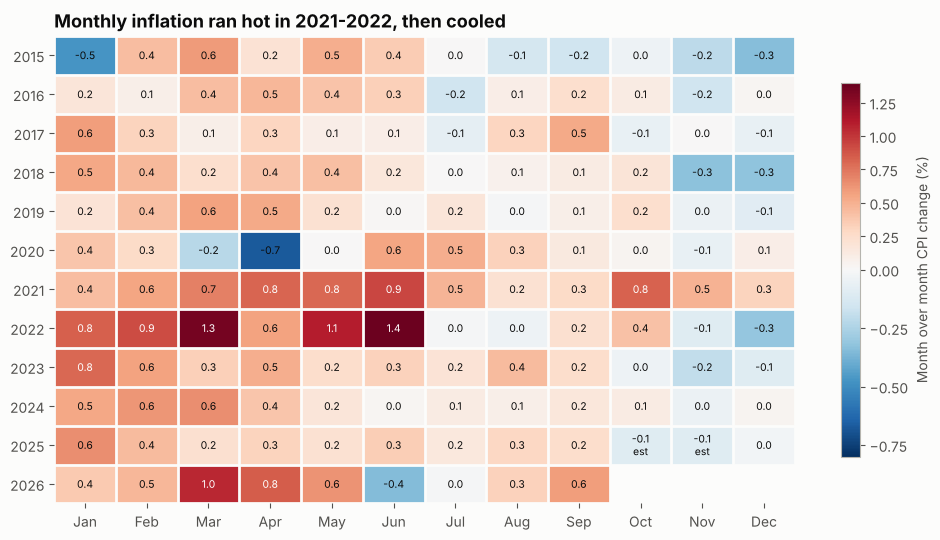

In [2]:
h = cpi[cpi["Date"] >= "2015-01-01"].copy()
h["Year"] = h["Date"].dt.year
h["Month"] = h["Date"].dt.month
grid = h.pivot(index="Year", columns="Month", values="MoM_Change_%")
est = h.pivot(index="Year", columns="Month", values="MoM_Uses_Estimate")

fig, ax = plt.subplots(figsize=(10, 5.5))
norm = TwoSlopeNorm(vmin=-0.8, vcenter=0, vmax=1.4)
im = ax.imshow(grid.values, cmap="RdBu_r", norm=norm, aspect="auto")
ax.set_xticks(range(12)); ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_yticks(range(len(grid))); ax.set_yticklabels(grid.index)
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.values[i, j]
        if np.isnan(v):
            continue
        v = round(v, 1) + 0.0
        txt = f"{abs(v) if v == 0 else v:.1f}" + ("\nest" if est.values[i, j] else "")
        ax.text(j, i, txt, ha="center", va="center", fontsize=7.5,
                color="white" if abs(v) > 0.7 else INK)
for s in ax.spines.values(): s.set_visible(False)
ax.set_xticks(np.arange(-.5, 12, 1), minor=True); ax.set_yticks(np.arange(-.5, len(grid), 1), minor=True)
ax.grid(which="minor", color=BG, linewidth=2); ax.tick_params(which="minor", length=0)
cb = fig.colorbar(im, ax=ax, shrink=0.8); cb.set_label("Month over month CPI change (%)", color=INK2)
ax.set_title("Monthly inflation ran hot in 2021-2022, then cooled", loc="left", fontsize=13, fontweight="bold", color=INK)
plt.tight_layout()
plt.savefig("images/py1_inflation_heatmap.png", dpi=150)
plt.show()

## 2. How often is the market scared? VIX fear zones

**Why it's useful:** the VIX line chart makes it look like the market is always spiking, because the spikes grab all the attention. Grouping every trading day since 1992 into zones answers a simpler question: what's normal? It turns out the VIX is above 30 (high fear) only about 8% of the time, and most days are calm or normal.

I start in 1992 to match the rest of my VIX work, since 1990-91 only had close values. Zones are common rule-of-thumb levels traders use, not official Cboe categories.

                     trading_days  share_%
CLOSE                                     
Calm (under 15)              2956     33.7
Normal (15-20)               2619     29.9
Elevated (20-30)             2491     28.4
High fear (over 30)           706      8.0


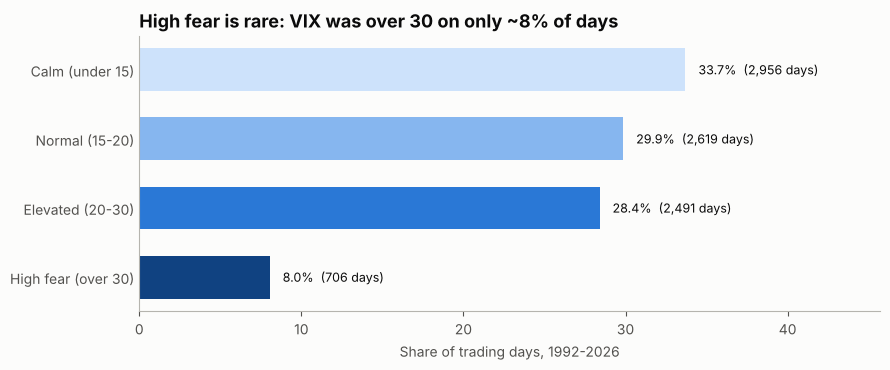

In [3]:
v = vix[vix["DATE"] >= "1992-01-01"]
bins = [0, 15, 20, 30, np.inf]
labels = ["Calm (under 15)", "Normal (15-20)", "Elevated (20-30)", "High fear (over 30)"]
zones = pd.cut(v["CLOSE"], bins=bins, labels=labels, right=False)
share = zones.value_counts(normalize=True).reindex(labels) * 100
counts = zones.value_counts().reindex(labels)
print(pd.DataFrame({"trading_days": counts, "share_%": share.round(1)}))

colors = ["#cde2fb", "#86b6ef", "#2a78d6", "#104281"]   # one hue, light = calm, dark = fear
fig, ax = plt.subplots(figsize=(9, 3.8))
bars = ax.barh(labels, share.values, color=colors, height=0.62)
for b, pct, n in zip(bars, share.values, counts.values):
    ax.text(b.get_width() + 0.8, b.get_y() + b.get_height()/2, f"{pct:.1f}%  ({n:,} days)", va="center", fontsize=9, color=INK)
ax.invert_yaxis()
ax.set_xlim(0, max(share.values) + 12)
ax.set_xlabel("Share of trading days, 1992-2026", color=INK2)
ax.tick_params(axis="y", length=0)
ax.set_title("High fear is rare: VIX was over 30 on only ~8% of days", loc="left", fontsize=13, fontweight="bold", color=INK)
plt.tight_layout()
plt.savefig("images/py2_vix_fear_zones.png", dpi=150)
plt.show()

## 3. Who produced the goals? PBA 2026 player breakdown

**Why it's useful:** a team total of 28 goals hides how the scoring was spread out. A stacked bar of goals + assists for every player who got at least one point shows it immediately: Kobi Thomas was involved in 21 of our 28 goals (17 goals, 4 assists). That's a real strength but also a risk, since our attack depends a lot on one player. My own line (1 assist) is in **bold**.

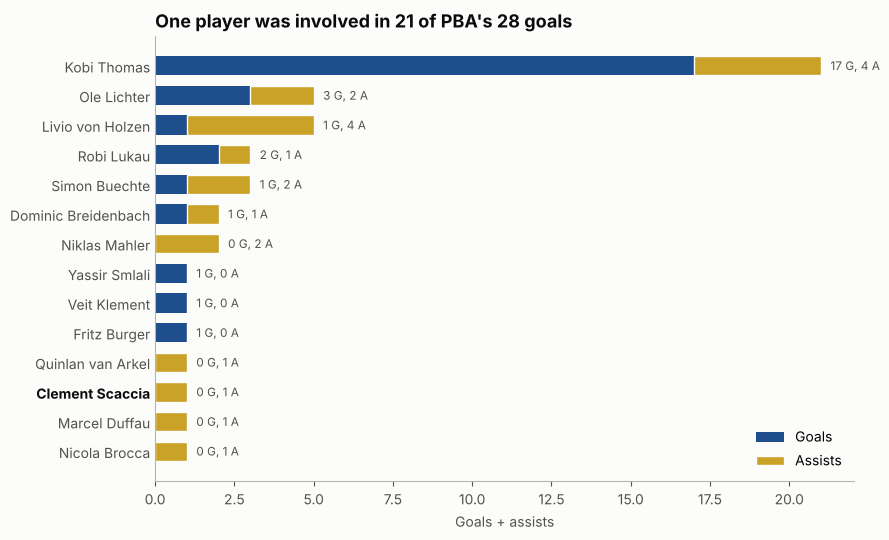

In [4]:
p = players[(players["G"] + players["A"]) > 0].copy()
p["Name"] = p["Player"].str.split(", ").str[1] + " " + p["Player"].str.split(", ").str[0]
p["GA"] = p["G"] + p["A"]
p = p.sort_values(["GA", "G"], ascending=True)

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(p["Name"], p["G"], color="#1f4e8c", label="Goals", height=0.65)
ax.barh(p["Name"], p["A"], left=p["G"], color="#c9a227", label="Assists", height=0.65, edgecolor=BG, linewidth=1)
for y, (g, a) in enumerate(zip(p["G"], p["A"])):
    ax.text(g + a + 0.3, y, f"{g} G, {a} A", va="center", fontsize=8.5, color=INK2)
for lbl in ax.get_yticklabels():
    if lbl.get_text() == "Clement Scaccia":
        lbl.set_fontweight("bold"); lbl.set_color(INK)
ax.set_xlabel("Goals + assists", color=INK2)
ax.tick_params(axis="y", length=0)
ax.legend(loc="lower right", frameon=False)
share = (p.loc[p["Name"] == "Kobi Thomas", ["G", "A"]].sum(axis=1).iloc[0])
ax.set_title(f"One player was involved in {share} of PBA's 28 goals", loc="left", fontsize=13, fontweight="bold", color=INK)
plt.tight_layout()
plt.savefig("images/py3_soccer_contributions.png", dpi=150)
plt.show()

## Summary

| Chart | Main takeaway | Why this chart type |
|---|---|---|
| Inflation heatmap | 2021-2022 stands out as the hot period, and spring 2020 had falling prices | shows 140+ monthly values at once, and the patterns by year and by month |
| VIX fear zones | the market is in "high fear" only ~8% of the time | turns 8,700+ daily values into one simple answer |
| Player breakdown | one player was involved in 21 of 28 goals | stacked bars show both the total and how it's split between goals and assists |